# EKF G/F con solubilidad variable · Perturbaciones en los coeficientes cinéticos

El EKF de referencia corresponde al caso de cuatro fuentes del notebook 04 de kalman_analysis. Los dos filtros usan R = 0,00218 (g/(L·h))², los mismos parámetros nominales, condiciones iniciales, covarianza inicial, observaciones y ventanas asimiladas. LAB019–021 son los lotes de desarrollo y LAB016–018 los de validación. Las varianzas proceden del ajuste exploratorio LAB004–009, condicionado a fijar Y(E/F).

En la variante de Lima, Qₖ = Gₖ Dθ Gₖᵀ reemplaza el aporte de los flujos. Cada columna de Gₖ deriva el estado al final del intervalo respecto de una tasa nominal. Se perturba cada coeficiente durante el intervalo completo de predicción, usualmente de cinco minutos, con particiones en eventos. Las perturbaciones se consideran independientes entre intervalos. El paso interno de RK4 es de hasta un minuto. La derivada ya incluye la duración del intervalo, por lo que el aporte no se vuelve a multiplicar por el paso de tiempo. Las varianzas locales aportan una escala exploratoria para esta hipótesis temporal.

Referencia: Lima et al., sección 2.4 y ecuación (5b), https://doi.org/10.21203/rs.3.rs-4419796/v1.

In [1]:
from pathlib import Path
import ast
import json
import os
import sys
from types import ModuleType

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import scipy
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/wine_fermentation").is_dir())
EKF = ROOT / "notebooks/EKF"
HERE = EKF / "kalman_analysis"
prefix = Path(os.environ["CONDA_PREFIX"]).resolve()
assert prefix.name.lower() == "fermentation" and Path(sys.prefix).resolve() == prefix
print(f"Kernel {prefix.name} · SciPy {scipy.__version__}")

# Load the existing helpers as Python functions. The filter below uses the
# vectorized NumPy transition from EKF05 and does not require Numba.
core_path = HERE / "analysis_core.py"
tree = ast.parse(core_path.read_text(encoding="utf-8"))
tree.body = [node for node in tree.body
             if not (isinstance(node, ast.ImportFrom) and node.module == "numba")]
for node in tree.body:
    if isinstance(node, ast.FunctionDef):
        node.decorator_list = [
            d for d in node.decorator_list
            if not (isinstance(d, ast.Call) and isinstance(d.func, ast.Name) and d.func.id == "njit")
        ]
core = ModuleType("analysis_core")
core.__file__ = str(core_path)
exec(compile(tree, str(core_path), "exec"), vars(core))

# Reuse the six-lot input preparation from the four-source comparison.
reference = HERE / "04_gf_variable_solubility_fourth_noise_source.source.ipynb"
reference_nb = nbformat.read(reference, as_version=4)
preparation = next(cell.source for cell in reference_nb.cells
                   if cell.cell_type == "code" and "DATA,CHEM,AUDIT,_=core.prepare(ROOT)" in cell.source)
assert preparation.count("import analysis_core as core") == 1
preparation = preparation.replace("import analysis_core as core", "")
exec(compile(preparation, str(reference), "exec"))

calibration = ROOT / "notebooks/diagnostics/zenteno_lab004_009_incertidumbre_exploratoria.ipynb"
saved_nb = nbformat.read(calibration, as_version=4)
saved = json.loads(saved_nb.cells[-1].outputs[-1].text)
rate_names = ["mu0", "betaG0", "betaF0"]
assert saved["orden_D_theta"] == rate_names
D_theta = np.array(saved["D_theta_Yef_fijo"], dtype=float)
np.testing.assert_array_equal(D_theta, np.diag(np.diag(D_theta)))
assert (np.diag(D_theta) > 0).all()
R = 0.00218
R_cell = next(cell.source for cell in reference_nb.cells
              if cell.cell_type == "code" and "R = 0.00218" in cell.source)
assert ast.literal_eval(ast.parse(R_cell).body[0].value) == R
theta = core.THETA
nominal = np.array([theta[name] for name in rate_names])
sigma_theta = np.sqrt(np.diag(D_theta))
SCALE = core.SCALE
scale_outer = np.outer(SCALE, SCALE)
KLA, GAIN = core.ARCHIVED_GAS
PCO2_BAR = 1.0
display(pd.DataFrame({"Nominal del EKF": nominal, "Varianza [h^-2]": np.diag(D_theta)},
                     index=rate_names))


Kernel fermentation · SciPy 1.13.1


,LAB,horizon_h,windows,updates,X0,N0,G0,F0,E0,pulse_h,dose_g_L,role
0,LAB019,166.000000,332,217,0.283162,0.230025,79.190000,78.970000,10.010194,64.333333,0.086486,Development
1,LAB020,172.333333,344,223,0.153342,0.225556,77.940000,79.520000,10.010194,71.666667,0.088889,Development
2,LAB021,166.000000,332,166,0.270000,0.231202,80.190000,81.040000,10.010194,47.500000,0.086486,Development
3,LAB016,151.100000,302,249,0.390000,0.214330,84.158815,88.341185,10.010194,56.935556,0.140000,Holdout
4,LAB017,141.000000,282,213,0.390000,0.214330,84.158815,88.341185,10.010194,56.933611,0.280000,Holdout
5,LAB018,141.000000,282,237,0.390000,0.214330,84.158815,88.341185,10.010194,56.931667,0.140000,Holdout


,Nominal del EKF,Varianza [h^-2]
mu0,0.094031,0.000010
betaG0,0.422437,0.001966
betaF0,0.623655,0.015310


In [2]:
# Reuse the equations from the vectorized G/F EKF. Supply one set of three
# rate coefficients per trajectory, with the other coefficients shared.
source05 = EKF / "05_zenteno_co2_variable_solubility.source.ipynb"
nb05 = nbformat.read(source05, as_version=4)
functions = {}
for cell in nb05.cells:
    if cell.cell_type == "code":
        for node in ast.parse(cell.source).body:
            if isinstance(node, ast.FunctionDef):
                functions[node.name] = ast.get_source_segment(cell.source, node)
for name in ("co2_saturation", "gas_exchange"):
    exec(compile(functions[name], str(source05), "exec"))

rates_source = functions["rates_ekf"]
for original, replacement in (
    ("def rates_ekf(w,t,T,S0):", "def rates_ekf(w,t,T,S0,rate_coefficients):"),
    ("theta['mu0']", "rate_coefficients[:, 0]"),
    ("theta['betaG0']", "rate_coefficients[:, 1]"),
    ("theta['betaF0']", "rate_coefficients[:, 2]"),
):
    assert rates_source.count(original) == 1
    rates_source = rates_source.replace(original, replacement)
exec(compile(rates_source, str(source05), "exec"))


def transition(points, rate_coefficients, start, end, data):
    """Integrate each trajectory with its own constant rates over this interval."""
    w = points * SCALE
    n = max(1, int(np.ceil((end - start) * 60 - 1e-7)))
    dt = (end - start) / n
    available = data["available"]
    temperatures = data["temperature"]
    for j in range(n):
        t = start + j * dt
        times = np.array([t, t + dt / 2, t + dt])
        indices = np.searchsorted(available, times + 1e-12, side="right") - 1
        if indices[0] < 0:
            raise ValueError("No hay temperatura causal al comienzo del intervalo")
        T0, Tm, T1 = temperatures[indices]
        S0 = data["S0"]
        k1 = rates_ekf(w, t, T0, S0, rate_coefficients)
        k2 = rates_ekf(w + dt * k1 / 2, t + dt / 2, Tm, S0, rate_coefficients)
        k3 = rates_ekf(w + dt * k2 / 2, t + dt / 2, Tm, S0, rate_coefficients)
        k4 = rates_ekf(w + dt * k3, t + dt, T1, S0, rate_coefficients)
        w = np.maximum(w + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6, 0.)
    return w / SCALE


def sensitivities(z, start, end, data, kinetic, relative_step=1e-4):
    state_step = 1e-5
    delta = np.eye(len(z)) * state_step
    lower = z - delta * (z >= state_step)[:, None]
    denominator = state_step * (1 + (z >= state_step))
    points = np.vstack([z, z + delta, lower])
    coefficients = np.tile(nominal, (len(points), 1))
    if kinetic:
        parameter_step = relative_step * nominal
        parameter_delta = np.diag(parameter_step)
        points = np.vstack([points, np.tile(z, (6, 1))])
        coefficients = np.vstack([coefficients, nominal + parameter_delta, nominal - parameter_delta])

    predicted = transition(points, coefficients, start, end, data)
    J = ((predicted[1:8] - predicted[8:15]) / denominator[:, None]).T
    G = ((predicted[15:18] - predicted[18:21]) / (2 * parameter_step[:, None])).T if kinetic else None
    return predicted[0], J, G


# Compare with the archived scalar RHS and transition in several regimes.
data = DATA["LAB019"]
for start, state in (
    (3., [0.4, .20, 90., 95., 15., .02, 0.]),
    (31., [1.8, .12, 65., 70., 36., .65, .01]),
    (75., [2.4, .03, 27., 43., 65., 1.0, .02]),
    (120., [.9, 0., 0., 12., 94., 1.2, .03]),
):
    w = np.asarray(state)
    z = w / SCALE
    temp = core.temperature_at(start, data["available"], data["temperature"])
    np.testing.assert_allclose(
        rates_ekf(w[None, :], start, temp, data["S0"], nominal[None, :])[0],
        core.rhs(w, temp, data["S0"], KLA, GAIN), atol=1e-13, rtol=1e-12,
    )
    end = start + 1 / 12
    zp, J, G = sensitivities(z, start, end, data, True)
    z_ref, J_ref = core.jacobian(z, start, end, data["available"], data["temperature"],
                                 data["S0"], KLA, GAIN, 1 / 60)
    np.testing.assert_allclose(zp, z_ref, atol=1e-13)
    np.testing.assert_allclose(J, J_ref, atol=1e-9)
    _, _, G_fine = sensitivities(z, start, end, data, True, relative_step=5e-5)
    np.testing.assert_allclose(G, G_fine, atol=5e-7, rtol=3e-3)
print("Verificadas la dinámica nominal, las sensibilidades y el paso de diferencias finitas.")


Verificadas la dinámica nominal, las sensibilidades y el paso de diferencias finitas.


In [3]:
BASE = "EKF actual"
LIMA = "EKF Lima"
cases = {BASE: False, LIMA: True}
flux_variances = np.square(core.BASE_SIGMA)
expected_amplitudes = [.003, .08, .08, .01, 0., 0.]
np.testing.assert_array_equal(core.BASE_SIGMA, expected_amplitudes)


def replay(data, kinetic):
    grid = data["grid"]
    z = data["initial"] / SCALE
    P = data["P0"] / scale_outer
    states = np.empty((len(grid), len(z)))
    covariance = np.empty((len(grid), len(z), len(z)))
    diag = np.full((len(grid), 7), np.nan)
    injected = np.zeros_like(covariance)
    for i, end in enumerate(grid):
        if i:
            start = grid[i - 1]
            before = z
            z, J, G = sensitivities(z, start, end, data, kinetic)
            if kinetic:
                # G already differentiates the integrated transition.
                scaled_G = G * sigma_theta
                Q = scaled_G @ scaled_G.T
            else:
                T = core.temperature_at(start, data["available"], data["temperature"])
                L = core.noise_L(before * SCALE, T, data["S0"], KLA, GAIN)
                Q = (end - start) * ((L * flux_variances) @ L.T) / scale_outer
            injected[i] = Q * scale_outer
            P = J @ P @ J.T + Q
            P = (P + P.T) / 2

        z[1] += data["doses"][i] / SCALE[1]
        if end > 0 and abs(end / .5 - round(end / .5)) < 1e-8:
            predicted = z[6] / .5
            innovation = data["y"][i] - predicted
            S = 4 * P[6, 6] + R
            clips = 0
            if data["update"][i]:
                K = 2 * P[:, 6] / S
                updated = z + K * innovation
                clips = np.count_nonzero(updated[:6] < 0)
                B = np.eye(len(z))
                B[:, 6] -= 2 * K
                P = B @ P @ B.T + np.outer(K, K) * R
                P = (P + P.T) / 2
                z = np.maximum(updated, 0)
            diag[i] = [predicted, innovation, S, innovation**2 / S, clips,
                       data["update"][i], data["valid"][i]]
            z[6] = 0.
            P[6, :] = P[:, 6] = 0.
        states[i] = z * SCALE
        covariance[i] = P * scale_outer
    assert np.isfinite(states).all() and np.isfinite(covariance).all()
    assert np.linalg.eigvalsh(injected).min() > -1e-9
    np.testing.assert_array_equal(diag[:, 5] == 1, data["update"])
    return (states, covariance, diag), injected


results = {case: {} for case in cases}
metric_rows, check_rows, injection_rows = [], [], []
for lab in LABS:
    print(f"Evaluando {lab}", flush=True)
    for case, kinetic in cases.items():
        result, injection = replay(DATA[lab], kinetic)
        metrics, checks, _ = core.diagnostics(DATA, CHEM, lab, result)
        assert checks["min_eigenvalue"] > -1e-7
        results[case][lab] = result
        metric_rows.append(metrics.assign(EKF=case, Grupo=ROLE[lab]))
        check_rows.append(dict(checks, EKF=case))
        total = np.diagonal(injection, axis1=1, axis2=2).sum(axis=0)
        injection_rows.append(dict(LAB=lab, EKF=case, **dict(zip(core.STATES, total))))

metrics = pd.concat(metric_rows, ignore_index=True)
keys = ["Grupo", "LAB", "variable", "unit"]
counts = metrics.pivot(index=keys, columns="EKF", values="n")
assert counts[BASE].equals(counts[LIMA])
rmse = metrics.pivot(index=keys, columns="EKF", values="RMSE")[[BASE, LIMA]]
means = rmse.groupby(level=["Grupo", "variable", "unit"]).mean()
# Confirm the four-source benchmark from the archived six-lot comparison.
reference_rmse = {("Development", "CO2", "g/(L h)"): .07399,
                  ("Holdout", "CO2", "g/(L h)"): .08002,
                  ("Development", "X", "g/L"): .71986,
                  ("Holdout", "X", "g/L"): .61737}
for key, value in reference_rmse.items():
    np.testing.assert_allclose(means.loc[key, BASE], value, atol=7e-6, rtol=0)
means["Cambio Lima [%]"] = 100 * (means[LIMA] / means[BASE] - 1)
print("RMSE medio por grupo con igual peso por lote")
display(means.round(5))
print("RMSE por lote y variable")
display(rmse.round(5))
display(pd.DataFrame(check_rows)[["LAB", "EKF", "updates", "mean_NIS", "clips"]].round(4))
print("Suma de varianzas de proceso inyectadas por estado a lo largo de cada lote")
display(pd.DataFrame(injection_rows).set_index(["LAB", "EKF"]).round(6))


Evaluando LAB019


Evaluando LAB020


Evaluando LAB021


Evaluando LAB016


Evaluando LAB017


Evaluando LAB018


... (3 outputs left out)

EKF                                  EKF actual  EKF Lima
Grupo       LAB    variable unit                         
Development LAB019 CO2      g/(L h)     0.06390   0.06539
                   E        g/L         4.31327   4.18778
                   F        g/L         5.33387   6.07591
                   G        g/L         4.24205   3.12415
                   GF       g/L         7.98078   7.54808
                   N        mg/L       20.01483  20.85265
                   X        g/L         0.65490   0.66859
            LAB020 CO2      g/(L h)     0.07034   0.06233
                   E        g/L         3.52061   3.42424
                   F        g/L         6.08464   6.44859
                   G        g/L         4.53780   3.51246
                   GF       g/L         8.25181   8.09422
                   N        mg/L       18.11179  18.57756
                   X        g/L         0.57051   0.57976
            LAB021 CO2      g/(L h)     0.08772   0.08278
                   E        g/L         3.12991   3.20746
                   F        g/L         4.54467   4.23944
                   G        g/L         6.19400   6.61623
                   GF       g/L         8.31084   8.10345
                   N        mg/L       13.23893  13.12089
                   X        g/L         0.93417   0.93923
Holdout     LAB016 CO2      g/(L h)     0.07386   0.06754
                   X        g/L         0.56065   0.55198
            LAB017 CO2      g/(L h)     0.08750   0.07849
                   X        g/L         0.81125   0.82014
            LAB018 CO2      g/(L h)     0.07870   0.07558
                   X        g/L         0.48022   0.46678

,LAB,EKF,updates,mean_NIS,clips
0,LAB019,EKF actual,217,1.1695,57
1,LAB019,EKF Lima,217,2.1767,15
2,LAB020,EKF actual,223,1.1300,16
3,LAB020,EKF Lima,223,1.6320,7
4,LAB021,EKF actual,166,3.0739,24
5,LAB021,EKF Lima,166,4.5584,43
6,LAB016,EKF actual,249,1.2043,156
7,LAB016,EKF Lima,249,1.6884,13
8,LAB017,EKF actual,213,1.8895,216
9,LAB017,EKF Lima,213,2.3526,0


Suma de varianzas de proceso inyectadas por estado a lo largo de cada lote


X         N         G         F         E        Cd  \
LAB    EKF                                                                      
LAB019 EKF actual  0.001494  0.000036  1.064001  1.063613  0.510918  0.001598   
       EKF Lima    0.000010  0.000000  0.052241  0.206388  0.065419  0.000032   
LAB020 EKF actual  0.001551  0.000037  1.104595  1.104192  0.530411  0.004760   
       EKF Lima    0.000007  0.000000  0.044046  0.173855  0.055117  0.000046   
LAB021 EKF actual  0.001494  0.000036  1.064001  1.063613  0.510918  0.040917   
       EKF Lima    0.000014  0.000000  0.058044  0.285315  0.087323  0.000024   
LAB016 EKF actual  0.001360  0.000033  0.968497  0.968144  0.465059  0.000849   
       EKF Lima    0.000017  0.000000  0.045748  0.402007  0.115134  0.000034   
LAB017 EKF actual  0.001269  0.000030  0.903760  0.903430  0.433973  0.023667   
       EKF Lima    0.000033  0.000001  0.057204  0.425101  0.123678  0.000032   
LAB018 EKF actual  0.001269  0.000030  0.903760  0.903430  0.433973  0.000639   
       EKF Lima    0.000017  0.000000  0.042520  0.385382  0.110078  0.000021   

                          I  
LAB    EKF                   
LAB019 EKF actual  0.178840  
       EKF Lima    0.024505  
LAB020 EKF actual  0.172251  
       EKF Lima    0.020698  
LAB021 EKF actual  0.165037  
       EKF Lima    0.032788  
LAB016 EKF actual  0.164047  
       EKF Lima    0.043089  
LAB017 EKF actual  0.142888  
       EKF Lima    0.046343  
LAB018 EKF actual  0.155631  
       EKF Lima    0.041353

## Trayectorias por lote

Las figuras muestran el flujo predicho antes de corregir y las estimaciones de los seis estados físicos. Glucosa más fructosa se calcula sumando ambos estados. Los rombos verdes de esa figura son estimaciones a partir de densidad. El RMSE y el MAE de G+F se calculan con las muestras de laboratorio, excluido el cero sustituido. En LAB016–018 solo hay muestras directas de biomasa entre los estados físicos evaluados. El CO₂ disuelto se muestra como estimación sin muestras directas. El acumulador interno de emisión se refleja en el flujo medio de cada ventana de 30 minutos.

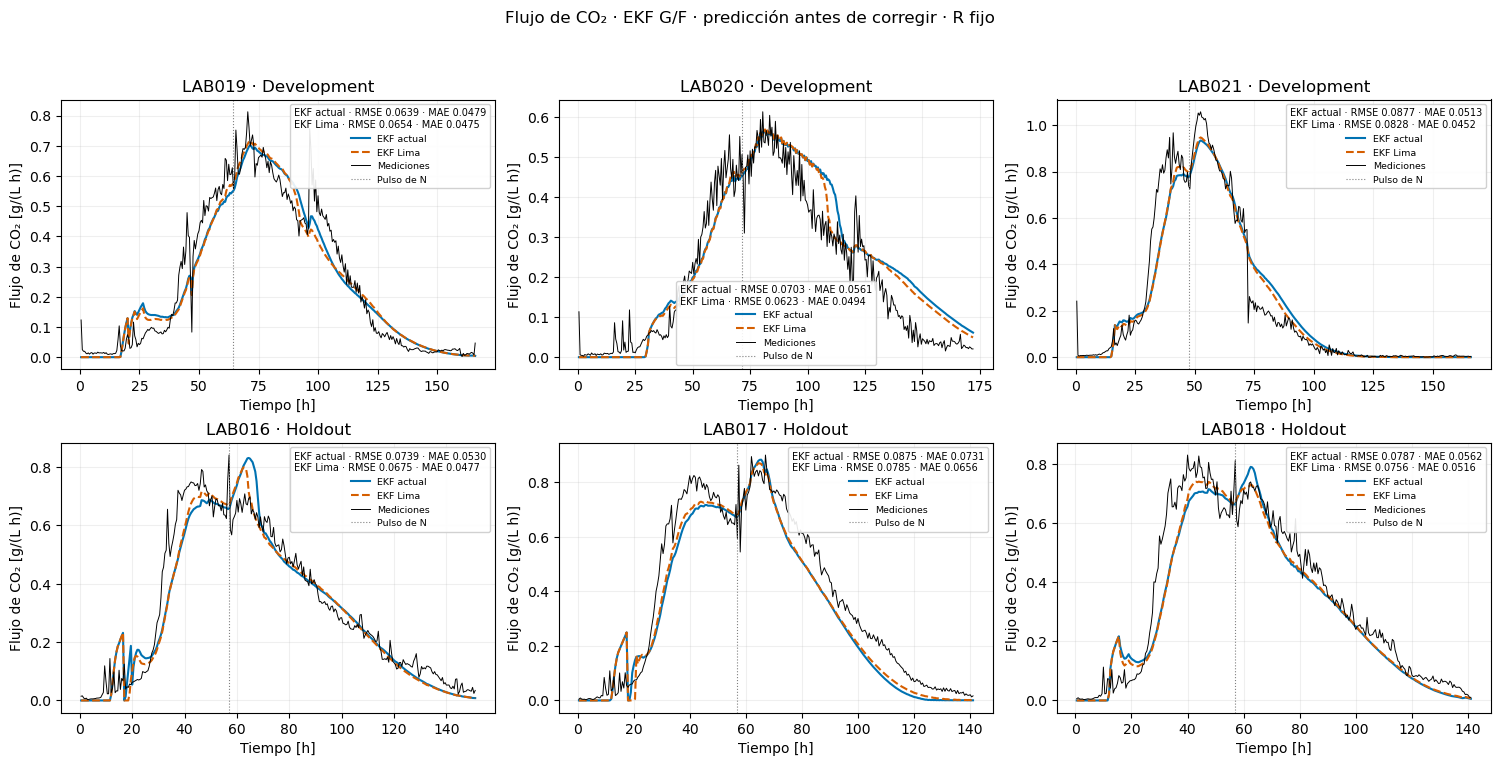

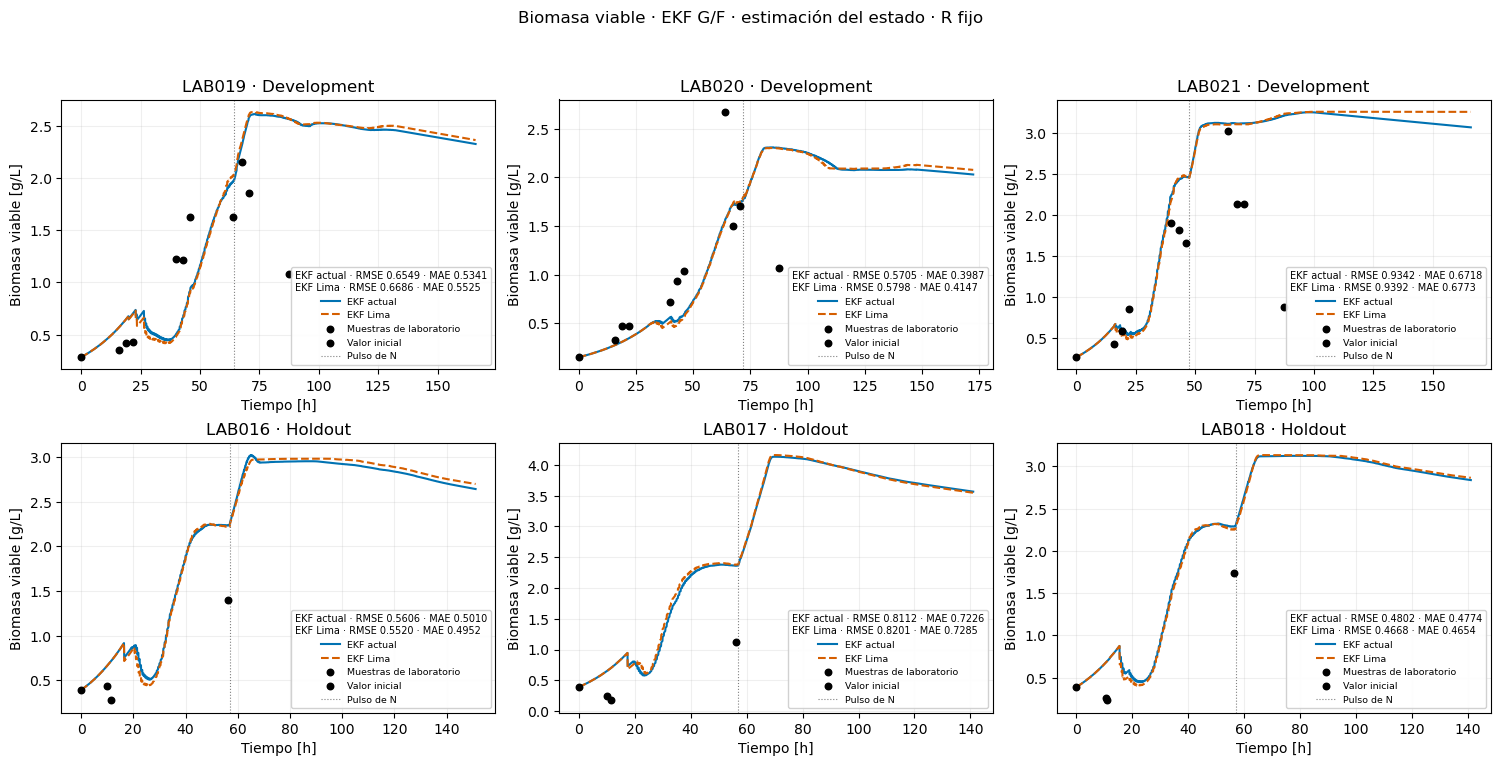

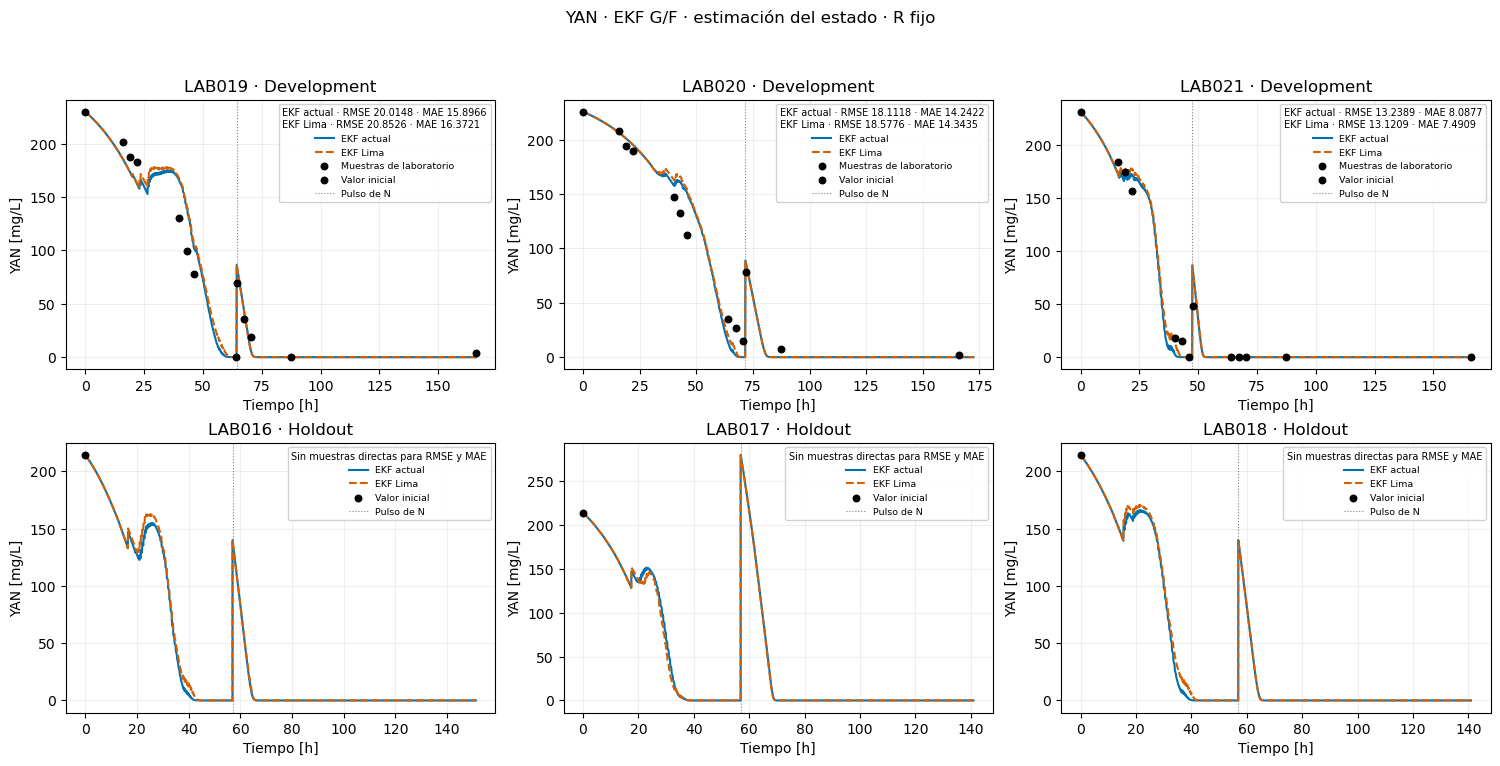

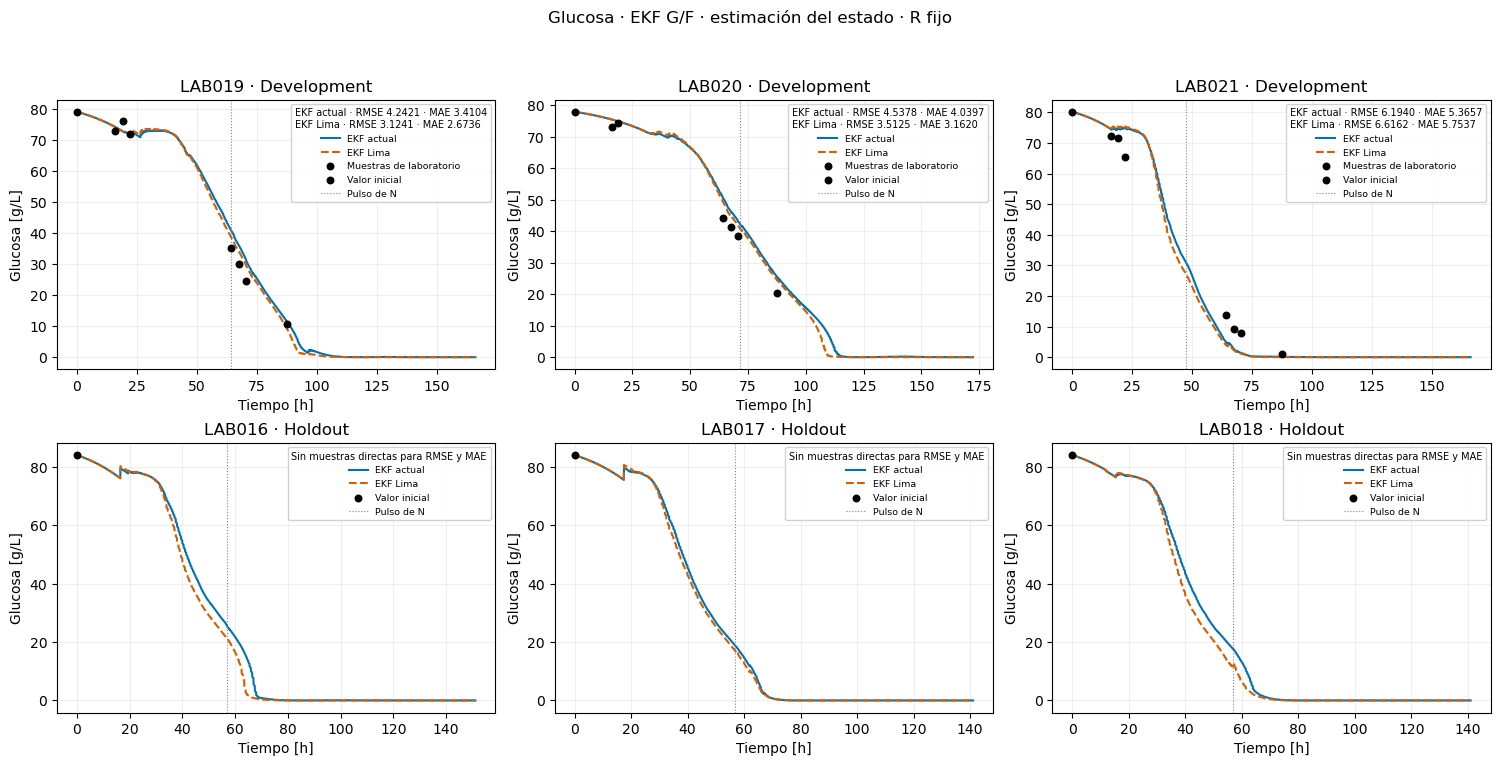

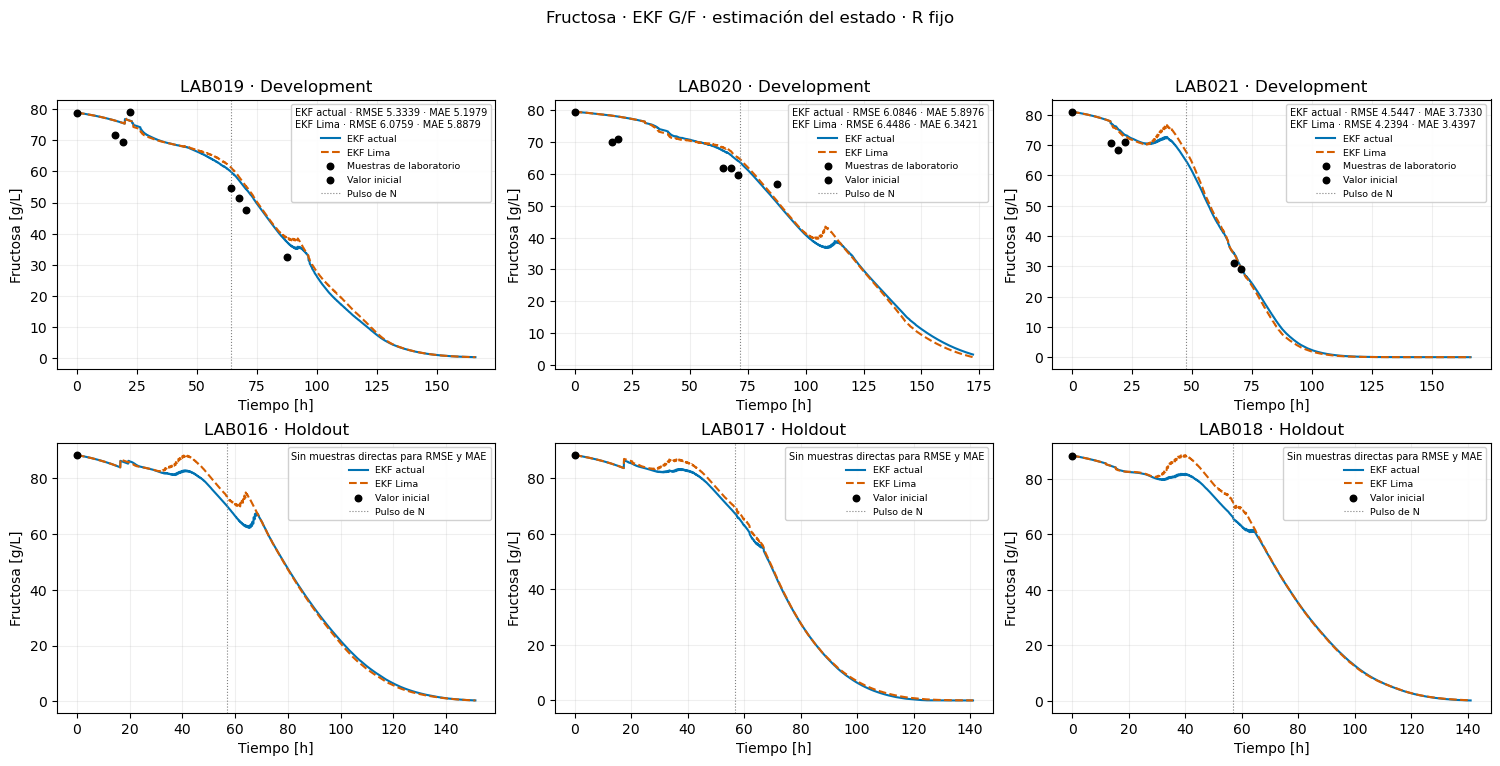

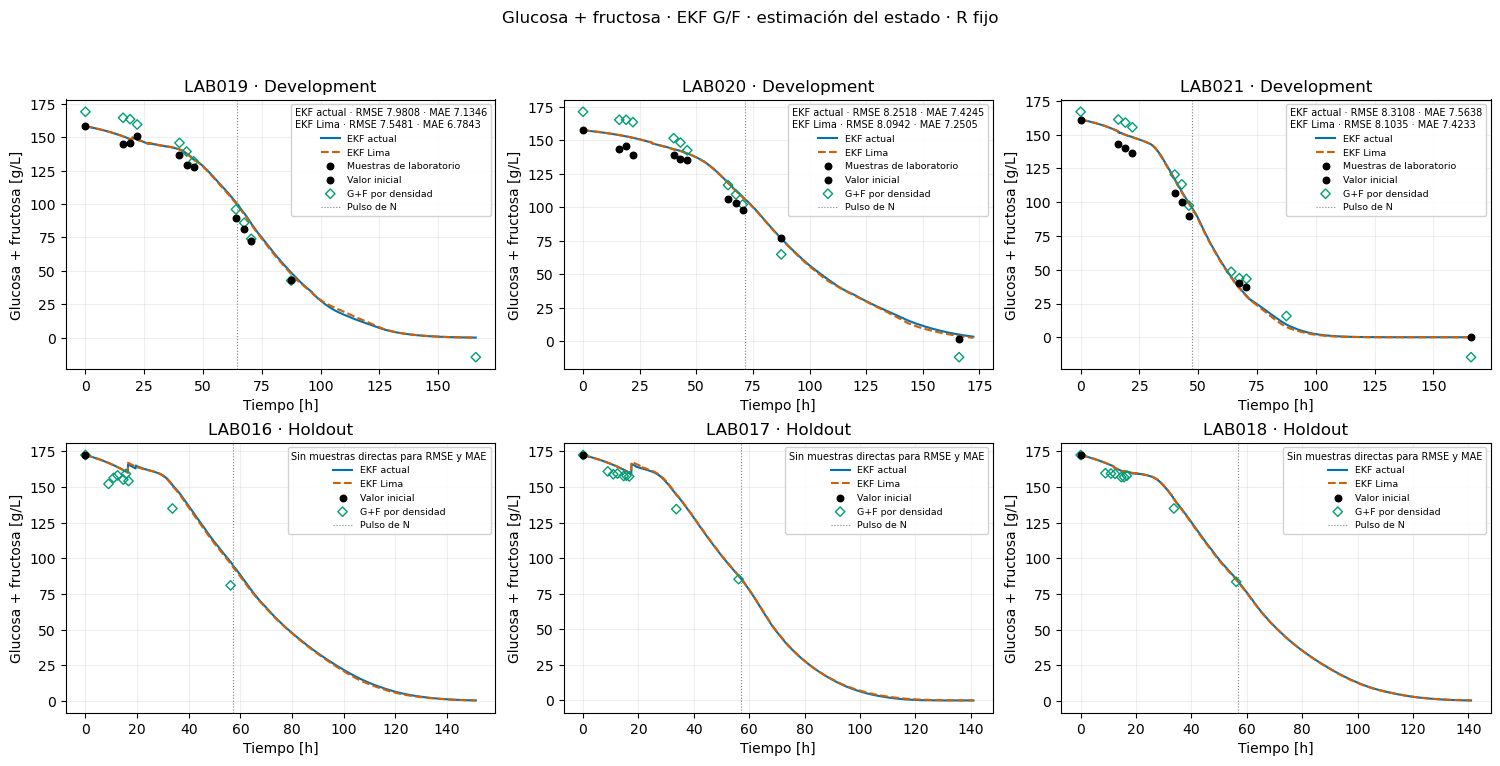

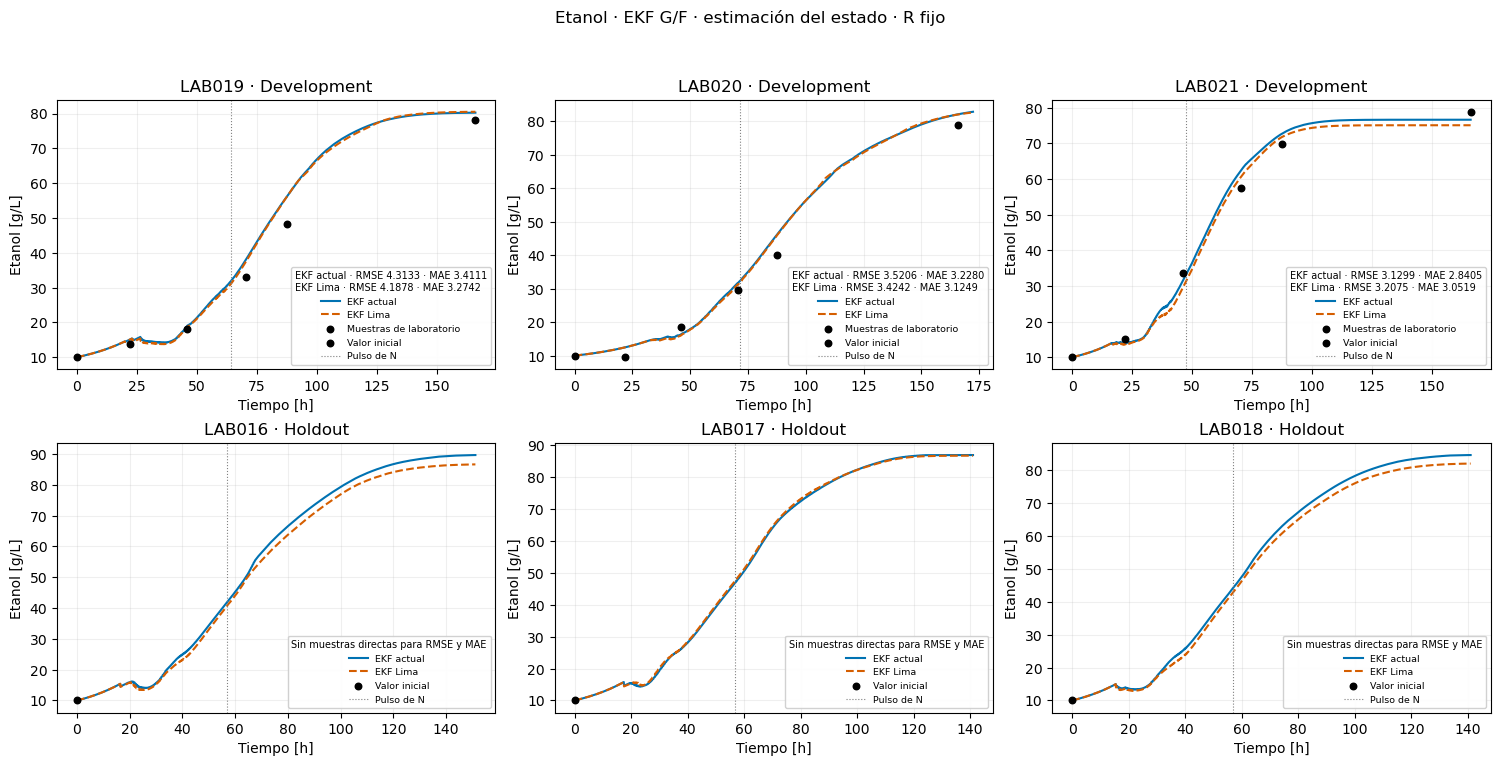

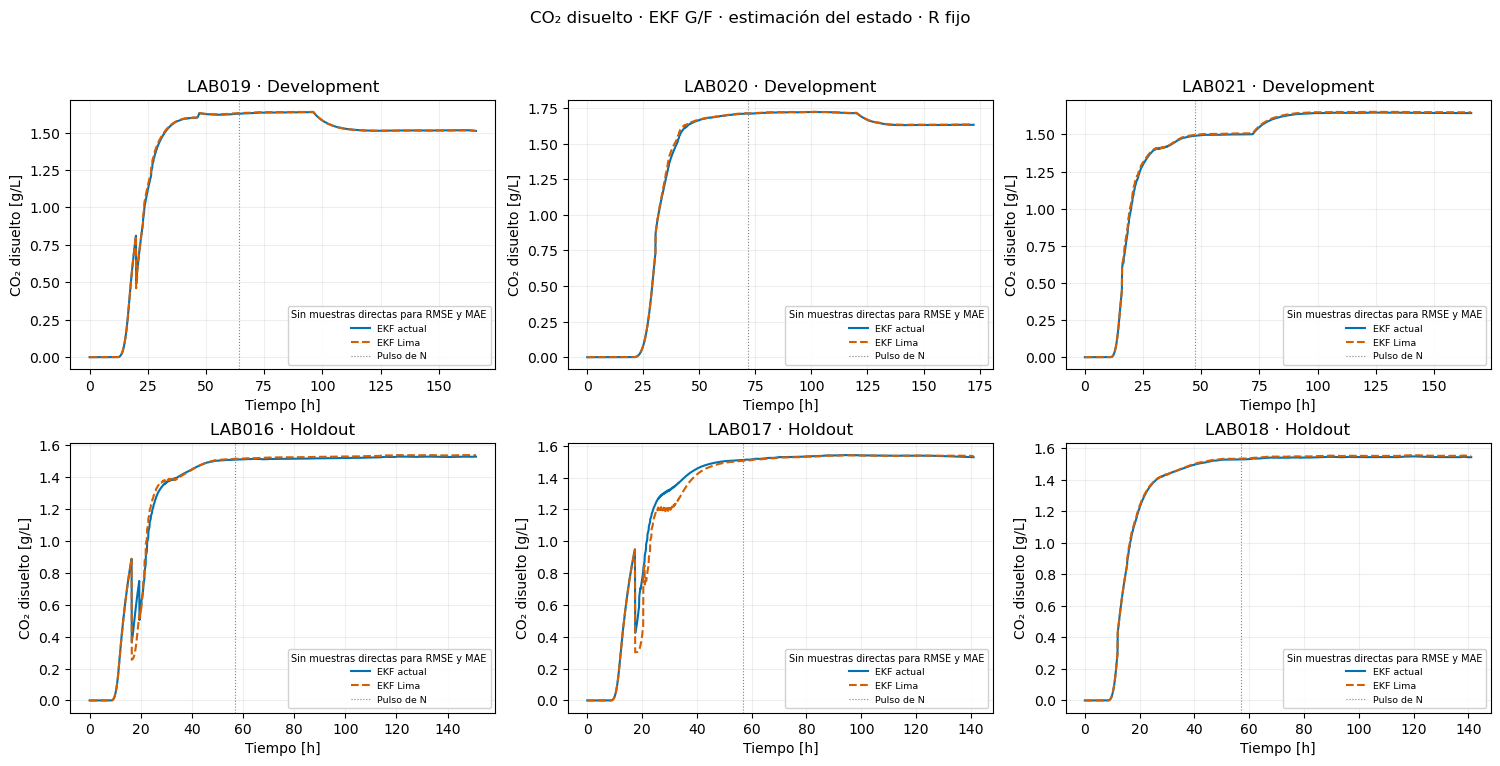

In [4]:
# Use the panel style of the six-lot comparison in kalman_analysis/04.
COLORS = {BASE: "#0072B2", LIMA: "#D55E00"}
STYLES = {BASE: "-", LIMA: "--"}

def state_curve(frame, state):
    if state == "GF":
        return frame[:, 2] + frame[:, 3]
    return frame[:, core.STATES.index(state)]


def panel(state, title, unit):
    factor = 1000 if state == "N" else 1
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.6))
    for ax, lab in zip(axes.flat, LABS):
        d = DATA[lab]
        grid = d["grid"]
        errors = []
        for case in cases:
            frame, _, diag = results[case][lab]
            if state == "CO2":
                mask = d["valid"] & np.isfinite(diag[:, 0])
                tx, prediction = grid[mask], diag[mask, 0]
            else:
                tx, prediction = grid, state_curve(frame, state)
            ax.plot(tx, factor * prediction, color=COLORS[case], ls=STYLES[case], lw=1.5, label=case)
            rows = metrics.loc[metrics.LAB.eq(lab) & metrics.variable.eq(state) & metrics.EKF.eq(case)]
            if len(rows):
                row = rows.iloc[0]
                errors.append(f"{case} · RMSE {row.RMSE:.4f} · MAE {row.MAE:.4f}")

        if state == "CO2":
            sensor = d["sensor"]
            ax.plot(sensor.t_h, sensor.measured, c="black", lw=.7, label="Mediciones")
        elif state in core.CHEM_COLS:
            column = core.CHEM_COLS[state]
            samples = CHEM.loc[CHEM.lab.eq(lab) & CHEM.t_h.gt(0) &
                               CHEM.t_h.le(d["horizon"])].dropna(subset=[column])
            if state == "GF":
                samples = samples.loc[~samples.GF_zero_substitution.astype(str).str.lower().eq("true")]
            if len(samples):
                ax.scatter(samples.t_h, factor * samples[column], c="black", s=22,
                           zorder=5, label="Muestras de laboratorio")
            initial = state_curve(d["initial"][None, :], state)[0]
            ax.scatter([0.], [factor * initial], c="black", s=22, zorder=5, label="Valor inicial")
            if state == "GF":
                density = DENSITY.loc[DENSITY.lab.eq(lab) &
                                      DENSITY.t_h.between(0, d["horizon"])].dropna(subset=["density_g_l"])
                if len(density):
                    ax.scatter(density.t_h, 2.5 * (density.density_g_l - 1000), marker="D",
                               facecolors="none", edgecolors="#009E73", s=23,
                               zorder=4, label="G+F por densidad")
        for time in grid[d["doses"] > 0]:
            ax.axvline(time, c="gray", ls=":", lw=.8, label="Pulso de N")
        handles, labels = ax.get_legend_handles_labels()
        unique = dict(zip(labels, handles))
        legend_title = "\n".join(errors) if errors else "Sin muestras directas para RMSE y MAE"
        ax.legend(unique.values(), unique.keys(), loc="best", fontsize=6.8,
                  title=legend_title, title_fontsize=7, framealpha=.9)
        ax.set(title=f"{lab} · {ROLE[lab]}", xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]")
        ax.grid(alpha=.2)
    context = "predicción antes de corregir" if state == "CO2" else "estimación del estado"
    fig.suptitle(f"{title} · EKF G/F · {context} · R fijo", y=.995)
    fig.tight_layout(pad=.7, rect=(0, 0, 1, .95))
    plt.show()


for state, title, unit in (
    ("CO2", "Flujo de CO₂", "g/(L h)"),
    ("X", "Biomasa viable", "g/L"),
    ("N", "YAN", "mg/L"),
    ("G", "Glucosa", "g/L"),
    ("F", "Fructosa", "g/L"),
    ("GF", "Glucosa + fructosa", "g/L"),
    ("E", "Etanol", "g/L"),
    ("Cd", "CO₂ disuelto", "g/L"),
):
    panel(state, title, unit)


## Innovaciones e incertidumbre predictiva

La innovación es \(\nu_k=y_k-\hat y_{k|k-1}\), el flujo medido menos el flujo predicho antes de corregir. Su varianza predicha es \(S_k=H_kP^-_kH_k^\top+R\). Como hay una sola observación por ventana, \(\mathrm{NIS}_k=\nu_k^2/S_k\) y su valor esperado bajo un modelo bien calibrado es aproximadamente 1. El NIS se calcula sobre las mismas ventanas asimiladas por ambos filtros. El RMSE de CO₂ de la tabla anterior usa todas las ventanas válidas.

Para identificar qué hace subir el NIS, la tabla incluye el RMSE de la innovación en las ventanas asimiladas, la media de \(\sqrt{S_k}\) y una comparación que toma los errores de Lima y los divide por la varianza \(S_k\) del EKF actual. El cociente se calcula ventana por ventana antes de promediar. Así se puede distinguir cuánto cambia por los errores y cuánto por la incertidumbre asignada.

In [5]:
nis_rows = []
for lab in LABS:
    update = DATA[lab]["update"]
    base_diag = results[BASE][lab][2][update]
    lima_diag = results[LIMA][lab][2][update]
    base_error, base_variance = base_diag[:, 1], base_diag[:, 2]
    lima_error, lima_variance = lima_diag[:, 1], lima_diag[:, 2]
    np.testing.assert_allclose(base_diag[:, 3], base_error**2 / base_variance)
    np.testing.assert_allclose(lima_diag[:, 3], lima_error**2 / lima_variance)
    nis_rows.append({
        "LAB": lab,
        "Ventanas": int(update.sum()),
        "RMSE innovación actual": np.sqrt(np.mean(base_error**2)),
        "RMSE innovación Lima": np.sqrt(np.mean(lima_error**2)),
        "Media √S actual": np.mean(np.sqrt(base_variance)),
        "Media √S Lima": np.mean(np.sqrt(lima_variance)),
        "NIS actual": np.mean(base_diag[:, 3]),
        "NIS Lima con S actual": np.mean(lima_error**2 / base_variance),
        "NIS Lima": np.mean(lima_diag[:, 3]),
    })
nis_comparison = pd.DataFrame(nis_rows).set_index("LAB")
display(nis_comparison.round(5))
print("RMSE de innovación y √S en g/(L·h). NIS sin unidades.")


,Ventanas,RMSE innovación actual,RMSE innovación Lima,Media √S actual,Media √S Lima,NIS actual,NIS Lima con S actual,NIS Lima
LAB,,,,,,,,
LAB019,217,0.07486,0.07728,0.07000,0.05339,1.16955,1.25126,2.17668
LAB020,223,0.07279,0.06540,0.07015,0.05262,1.12997,0.91383,1.63200
LAB021,166,0.12173,0.11485,0.07151,0.05796,3.07390,2.72518,4.55836
LAB016,249,0.07688,0.06964,0.06989,0.05614,1.20433,1.00458,1.68843
LAB017,213,0.09527,0.08449,0.07073,0.05731,1.88948,1.48236,2.35259
LAB018,237,0.08236,0.07903,0.07077,0.05647,1.38871,1.28164,2.25366


RMSE de innovación y √S en g/(L·h). NIS sin unidades.
